In [30]:
import numpy as np
import torch
import pandas as pd
from sklearn.datasets import make_swiss_roll
import matplotlib.pyplot as plt

In [40]:
n_samples = 10000
data, _ = make_swiss_roll(n_samples)

In [41]:
data = data[:,[2,0]]/10
data =data*np.array([1,-1])

In [42]:
data

array([[-0.42850143, -0.32129224],
       [-0.98566737, -0.60070511],
       [ 0.78632016,  0.00753386],
       ...,
       [-0.80811758, -0.86163737],
       [-0.73259663,  0.7131147 ],
       [ 0.79163861,  0.10657727]], shape=(10000, 2))

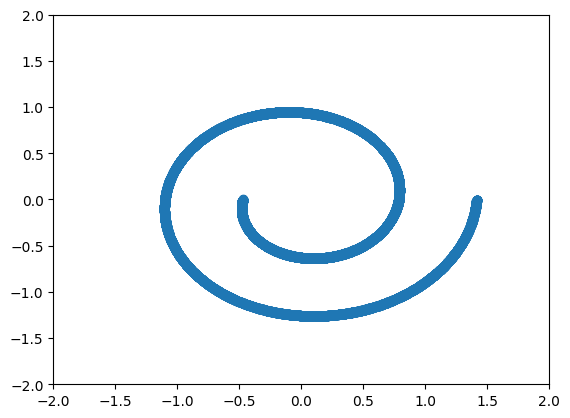

In [43]:
plt.scatter(data[:,0],data[:,1])
plt.xlim([-2,2])
plt.ylim([-2,2])
plt.show()

In [48]:
def forward_process(data,T,betas):

    for t in range(T):
        beta_t = betas[t]
        mu =data * np.sqrt(1-beta_t)
        std =np.sqrt(beta_t)
        data = mu + torch.randn_like(data)*std
    return data

In [50]:
T=40
betas = torch.sigmoid(torch.linspace(-18, 10, T)) * (3e-1 - 1e-5) + 1e-5
xT = forward_process(torch.from_numpy(data), T, betas)

C:\Users\Welcome\AppData\Local\Temp\ipykernel_12156\591862251.py:5: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  mu =data * np.sqrt(1-beta_t)
C:\Users\Welcome\AppData\Local\Temp\ipykernel_12156\591862251.py:6: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  std =np.sqrt(beta_t)


In [51]:
print(xT.mean(0))
print(xT.std(0))

tensor([-0.0011, -0.0320], dtype=torch.float64)
tensor([1.0046, 1.0078], dtype=torch.float64)


(-2.0, 2.0)

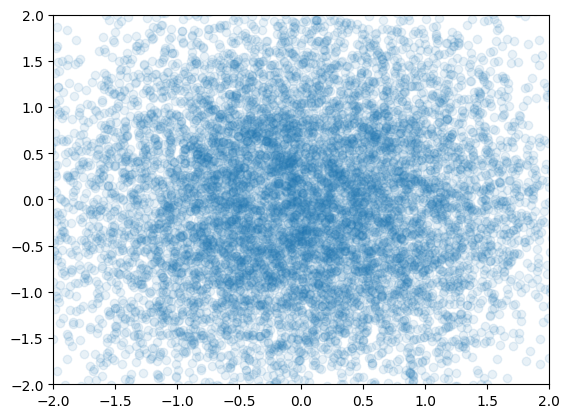

In [52]:
plt.scatter(xT[:, 0], xT[:, 1], alpha=0.1)
plt.xlim([-2, 2])
plt.ylim([-2, 2])